# The crash snapshot

Reads the directory the canary wrote when it stopped the run,
`<snapshots>_alarm/pe=*/n=<step>/`, and answers four questions in order:

1. **what went out of bounds**, where, and how many cells,
2. **is it one cell, a strait, or a patch** -- the geometry decides the cause,
3. **what does the column look like**, and what does the cell's history in the
   ordinary snapshots before it look like,
4. **is the surface forcing over the top cell thickness big enough to explain
   it**, which is the one candidate a 2 m top cell brings that the 4 degree
   runs did not have.

The dump holds `u, v, w, temp, salt, p_h, p_s, tke, K_diss_E, K_diss_L,
kappaH_tke, kappaM_tke, forc_temp_surface, forc_salt_surface, taux, tauy`,
one `.npy` per rank per field, plus `t.npy` and `why.txt`. The block layout
is the ordinary raw snapshot's, so everything here works on those too: point
`ALARMDIR` at a `raw_ocean_*_seg*` directory and set `STEP` to compare the
crash with a healthy record.

In [1]:
import os, glob, re
import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset

RUNDIR   = '/work/uo0780/u241155/pyOM3_real/icon01_spinup'
GRIDFILE = os.path.join(RUNDIR, 'grid_topo.nc')
ALARMGLOB = 'raw_ocean_icon01_seg*_alarm'   # the canary's dump
SNAPGLOB  = 'raw_ocean_icon01_seg*'         # the ordinary snapshots, for the history
STEP      = None                            # None = the newest step in the dump
OCEAN_DT  = None                            # None = taken from t.npy and the step

# the bounds the canary used (coupler_loop.CANARY_BOUNDS)
BOUNDS = dict(u=(-10.0, 10.0), v=(-10.0, 10.0),
              temp=(-5.0, 60.0), salt=(1.0, 45.0))

plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['image.cmap'] = 'RdYlBu_r'

## The dump, the grid and the block loader

In [2]:
alarms = sorted(d for d in glob.glob(os.path.join(RUNDIR, ALARMGLOB)) if os.path.isdir(d))
if not alarms:
    raise SystemExit('no alarm directory matching %s in %s' % (ALARMGLOB, RUNDIR))
ALARMDIR = alarms[-1]
steps = sorted({int(re.search(r'n=(\d+)$', p).group(1))
                for p in glob.glob(os.path.join(ALARMDIR, 'pe=*', 'n=*'))})
step = steps[-1] if STEP is None else STEP
NPE = len(glob.glob(os.path.join(ALARMDIR, 'pe=*')))

# the axes live in the ordinary snapshot directory, not in the dump
segs = sorted(glob.glob(os.path.join(RUNDIR, SNAPGLOB)))
segs = [d for d in segs if not d.endswith('_alarm') and
        os.path.exists(os.path.join(d, 'xt.npy'))]
AXDIR = segs[-1]
xt = np.load(os.path.join(AXDIR, 'xt.npy'))
yt = np.load(os.path.join(AXDIR, 'yt.npy'))
zt = np.load(os.path.join(AXDIR, 'zt.npy'))              # height above the bottom
npx, npy = np.load(os.path.join(AXDIR, 'decomposition.npy'))
nx, ny, nz = len(xt), len(yt), len(zt)

with Dataset(GRIDFILE) as f:
    kbot = np.asarray(f.variables['kbot'][:], int)
    dzt  = np.asarray(f.variables['dzt'][:], float)      # bottom first

depth_of = dzt.sum() - zt                                # metres below the surface
wet = (np.arange(nz)[:, None, None] >= (kbot - 1)[None]) & (kbot > 0)[None]
below = np.cumsum(dzt[::-1])[::-1]
col_depth = np.where(kbot > 0, below[np.clip(kbot - 1, 0, nz - 1)], 0.0)
nwet_col = np.where(kbot > 0, nz - kbot + 1, 0)

t_s = float(np.load(os.path.join(ALARMDIR, 'pe=0', 'n=%d' % step, 't.npy')))
dt = OCEAN_DT if OCEAN_DT else (t_s/step if step else float('nan'))
why = open(os.path.join(ALARMDIR, 'pe=0', 'n=%d' % step, 'why.txt')).read().strip()
print('%s   step %d   t = %.4f d   dt = %.1f s   %d ranks'
      % (os.path.basename(ALARMDIR), step, t_s/86400.0, dt, NPE))
print('why.txt: %s' % why)
print('grid %d x %d x %d on %d x %d ranks | top cell %.2f m | deepest column %.0f m'
      % (nx, ny, nz, npx, npy, dzt[-1], col_depth.max()))

raw_ocean_icon01_seg0000000_alarm   step 2416   t = 4.0267 d   dt = 144.0 s   7650 ranks
why.txt: coupling step 2416, 2 cells outside the canary bounds
grid 3600 x 2295 x 128 on 90 x 85 ranks | top cell 2.05 m | deepest column 6100 m


In [3]:
x_blk, y_blk = (nx-1)//npx + 1, (ny-1)//npy + 1
BLOCKS = []
for by in range(npy):
    for bx in range(npx):
        BLOCKS.append((by*npx + bx, by*y_blk, min((by+1)*y_blk, ny),
                       bx*x_blk, min((bx+1)*x_blk, nx)))

def _npy(pe, var, d=None, n=None):
    return os.path.join(d or ALARMDIR, 'pe=%d' % pe, 'n=%d' % (step if n is None else n),
                        '%s.npy' % var)

def load(var, k=None, d=None, n=None):
    """Global field from the per-rank blocks: one level (0 = sea floor,
    -1 = surface), a 2-D field, or the whole 3-D field with k=None."""
    out = None
    for pe, j0, j1, i0, i1 in BLOCKS:
        a = np.load(_npy(pe, var, d, n), mmap_mode='r')
        if a.ndim == 2:
            if out is None: out = np.empty((ny, nx))
            out[j0:j1, i0:i1] = a
        elif k is None:
            if out is None: out = np.empty((nz, ny, nx))
            out[:, j0:j1, i0:i1] = a
        else:
            if out is None: out = np.empty((ny, nx))
            out[j0:j1, i0:i1] = a[k]
    return out

def block_of(j, i):
    for pe, j0, j1, i0, i1 in BLOCKS:
        if j0 <= j < j1 and i0 <= i < i1:
            return pe, j - j0, i - i0
    raise IndexError((j, i))

def mask(a, k=None):
    m = wet if a.ndim == 3 else (wet[k] if k is not None else kbot > 0)
    return np.where(m, a, np.nan)

print('fields in the dump:', sorted(os.path.basename(p)[:-4] for p in
      glob.glob(os.path.join(ALARMDIR, 'pe=0', 'n=%d' % step, '*.npy'))))

fields in the dump: ['K_diss_E', 'K_diss_L', 'forc_salt_surface', 'forc_temp_surface', 'kappaH_tke', 'kappaM_tke', 'p_h', 'p_s', 'salt', 't', 'taux', 'tauy', 'temp', 'tke', 'u', 'v', 'w']


## 1. What went out of bounds

One pass over the blocks per field. For each field: how many cells are
non-finite, how many are outside the canary bounds, and the worst ten, with
their position, level, the column's depth and how many of the four horizontal
neighbours are wet at that level. `n_open` is the number that matters: 0 to 2
means the cell can barely exchange sideways, which is the signature of a
strait or a one-cell puddle rather than of a physical instability.

In [4]:
# ONE READ OF EACH BLOCK, IN PARALLEL. The scan is I/O bound: 4 fields x
# n_pes files of one block each, ~50 GB at 1/10 degree on 7650 ranks, so a
# serial loop is ten minutes and a thread pool is under one. numpy releases
# the GIL in isfinite/min/max, so threads are the right tool here.
#   NTHREAD   raise it until the time stops falling (Lustre, not the CPU)
#   FIELDS    only the ones with bounds; w and tke have none, so they only
#             cost time. Add them back if you want their extremes.
FIELDS  = ('u', 'v', 'temp', 'salt')
NTHREAD = 32

from concurrent.futures import ThreadPoolExecutor
import time as _time

def _scan_block(arg):
    """(non-finite count, out-of-bounds count, up to CANDIDATES hits) of one
    rank's block. The cheap min/max test comes first, so a healthy block is
    one pass and nothing else."""
    pe, j0, j1, i0, i1 = arg
    w = wet[:, j0:j1, i0:i1]
    nnan = nbad = 0
    hits = []
    for nm in FIELDS:
        
        lo, hi = BOUNDS.get(nm, (-np.inf, np.inf))
        a = np.asarray(np.load(_npy(pe, nm), mmap_mode='r'))
        aw = np.where(w, a, 0.0)
        if np.isfinite(aw).all() and aw.min() >= lo and aw.max() <= hi:
            continue                       # the common case, nothing to locate
        nan = w & ~np.isfinite(a)
        out = w & np.isfinite(a) & ((a < lo) | (a > hi))
        nnan += int(nan.sum()); nbad += int(out.sum())
        m = nan | out
        idx = np.argwhere(m)
        if len(idx) > CANDIDATES:          # keep the largest, not the first
            v = np.abs(np.nan_to_num(a[m], nan=1e30))
            idx = idx[np.argsort(-v)[:CANDIDATES]]
        for k, j, i in idx:
            hits.append((abs(float(np.nan_to_num(a[k, j, i], nan=1e30))),
                         nm, int(k), j0 + int(j), i0 + int(i), float(a[k, j, i])))
    return nnan, nbad, hits

CANDIDATES = 20                            # kept per block, before the global sort
_t = _time.time()
with ThreadPoolExecutor(NTHREAD) as ex:
    res = list(ex.map(_scan_block, BLOCKS))
nnan = sum(r[0] for r in res); nbad = sum(r[1] for r in res)
worst = sorted((h for r in res for h in r[2]), reverse=True)
print('scanned %d blocks x %d fields in %.1f s' % (len(BLOCKS), len(FIELDS), _time.time() - _t))
print('non-finite %d | outside the canary bounds %d | blocks with a hit %d'
      % (nnan, nbad, sum(1 for r in res if r[2])))
by_field = {}
for _, nm, *_r in worst:
    by_field[nm] = by_field.get(nm, 0) + 1
if by_field:
    print('candidates by field: ' + ', '.join('%s %d' % kv for kv in sorted(by_field.items())))

print('\nthe worst cells:')
for _, nm, k, j, i, val in worst[:10]:
    nb = sum(int(wet[k, min(max(j+dj, 0), ny-1), (i+di) % nx])
             for dj, di in ((0, 1), (0, -1), (1, 0), (-1, 0)))
    print('  %-5s = %12.4e  lon %8.3f lat %8.3f  k=%3d (%.1f m)  column %.0f m '
          '(%d levels)  n_open %d'
          % (nm, val, xt[i], yt[j], k, depth_of[k], col_depth[j, i],
             nwet_col[j, i], nb))
if not worst:
    print('  nothing outside the bounds in this record -- is STEP the alarm step?')


scanned 7650 blocks x 4 fields in 17.6 s
non-finite 0 | outside the canary bounds 2 | blocks with a hit 1
candidates by field: salt 2

the worst cells:
  salt  =   4.7091e+01  lon -150.200 lat  -76.248  k=109 (57.0 m)  column 589 m (62 levels)  n_open 4
  salt  =   4.5710e+01  lon -150.200 lat  -76.248  k=107 (66.4 m)  column 589 m (62 levels)  n_open 4


## 2. One cell, a strait, or a patch

The map is the vertical maximum of |u| and the vertical extremes of temp and
salt, so a single bad cell anywhere in the column shows up. The histogram of
`n_open` over the offending cells is the discriminator: all at 0 to 2 means
geometry, spread over 3 to 4 means the water column itself.

offending cells by open neighbours: 0 open: 0, 1 open: 0, 2 open: 0, 3 open: 0, 4 open: 2
0 of 2 sit in columns of <= 20 levels, median column depth 589 m


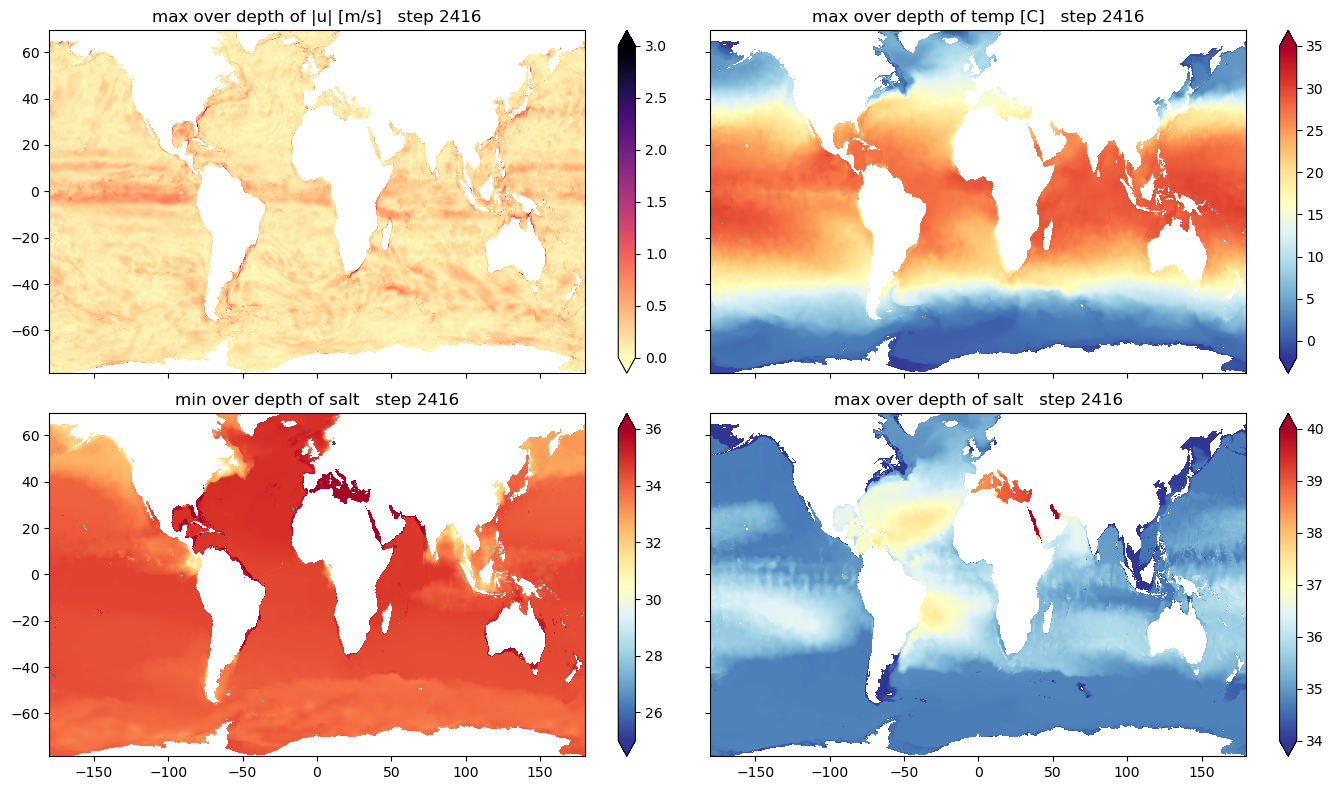

In [5]:
umax2 = np.zeros((ny, nx)); tmin2 = np.full((ny, nx), np.nan)
tmax2 = np.full((ny, nx), np.nan); smin2 = np.full((ny, nx), np.nan)
smax2 = np.full((ny, nx), np.nan)
for pe, j0, j1, i0, i1 in BLOCKS:
    w = wet[:, j0:j1, i0:i1]
    u = np.asarray(np.load(_npy(pe, 'u'), mmap_mode='r'))
    v = np.asarray(np.load(_npy(pe, 'v'), mmap_mode='r'))
    T = np.where(w, np.asarray(np.load(_npy(pe, 'temp'), mmap_mode='r')), np.nan)
    S = np.where(w, np.asarray(np.load(_npy(pe, 'salt'), mmap_mode='r')), np.nan)
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)   # all-dry blocks
        umax2[j0:j1, i0:i1] = np.nanmax(np.where(w, np.hypot(u, v), 0.0), axis=0)
        tmin2[j0:j1, i0:i1] = np.nanmin(T, axis=0); tmax2[j0:j1, i0:i1] = np.nanmax(T, axis=0)
        smin2[j0:j1, i0:i1] = np.nanmin(S, axis=0); smax2[j0:j1, i0:i1] = np.nanmax(S, axis=0)

fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for a, fld, ttl, kw in ((ax[0,0], mask(umax2), 'max over depth of |u| [m/s]',
                         dict(vmin=0, vmax=3, cmap='magma_r')),
                        (ax[0,1], tmax2, 'max over depth of temp [C]', dict(vmin=-2, vmax=35)),
                        (ax[1,0], smin2, 'min over depth of salt', dict(vmin=25, vmax=36)),
                        (ax[1,1], smax2, 'max over depth of salt', dict(vmin=34, vmax=40))):
    h = a.pcolormesh(xt, yt, fld, shading='auto', **kw)
    plt.colorbar(h, ax=a, extend='both'); a.set_title('%s   step %d' % (ttl, step))
fig.tight_layout()

if worst:
    nb = []
    for _, nm, k, j, i, val in worst:
        nb.append(sum(int(wet[k, min(max(j+dj, 0), ny-1), (i+di) % nx])
                      for dj, di in ((0, 1), (0, -1), (1, 0), (-1, 0))))
    nb = np.array(nb)
    print('offending cells by open neighbours: ' +
          ', '.join('%d open: %d' % (o, int((nb == o).sum())) for o in range(5)))
    print('%d of %d sit in columns of <= 20 levels, median column depth %.0f m'
          % (int(sum(nwet_col[j, i] <= 20 for _, _, _, j, i, _ in worst)), len(worst),
             float(np.median([col_depth[j, i] for _, _, _, j, i, _ in worst]))))

## 3. The offending column, and its surroundings

A window around the worst cell: the field at its level, the column depth, and
the full profile of temp, salt, u, v and the TKE diffusivity. A cold-start
artefact of the initial condition shows as a density front at one level; a
time-step problem shows as a two-cell sawtooth in the vertical, strongest at
the thinnest cells near the surface.

profile of the column, surface first (depth, temp, salt, u, v, w):
      1.0 m    -1.494    33.902    -0.2771    0.6799   9.885e-07
      3.1 m    -1.487    33.902    -0.2631    0.6665   8.010e-04
      5.3 m    -1.482    33.904    -0.2519    0.6636   1.637e-03
      7.6 m    -1.474    33.909    -0.2422    0.6677   2.516e-03
     10.0 m    -1.469    33.910    -0.2341    0.6769   3.442e-03
     12.5 m    -1.463    33.930    -0.2284    0.6807   4.419e-03
     15.1 m    -1.462    33.870    -0.2249    0.6817   5.440e-03
     17.8 m    -1.456    34.067    -0.2236    0.6836   6.496e-03
     20.6 m    -1.457    33.620    -0.2242    0.6830   7.586e-03
     23.6 m    -1.449    34.422    -0.2272    0.6836   8.722e-03
     26.7 m    -1.451    33.697    -0.2318    0.6827   9.902e-03
     29.9 m    -1.449    33.654    -0.2359    0.6835   1.110e-02
     33.3 m    -1.442    35.038    -0.2405    0.6816   1.233e-02
     36.8 m    -1.452    31.369    -0.2434    0.6817   1.360e-02
     40.5 m    -1.437  

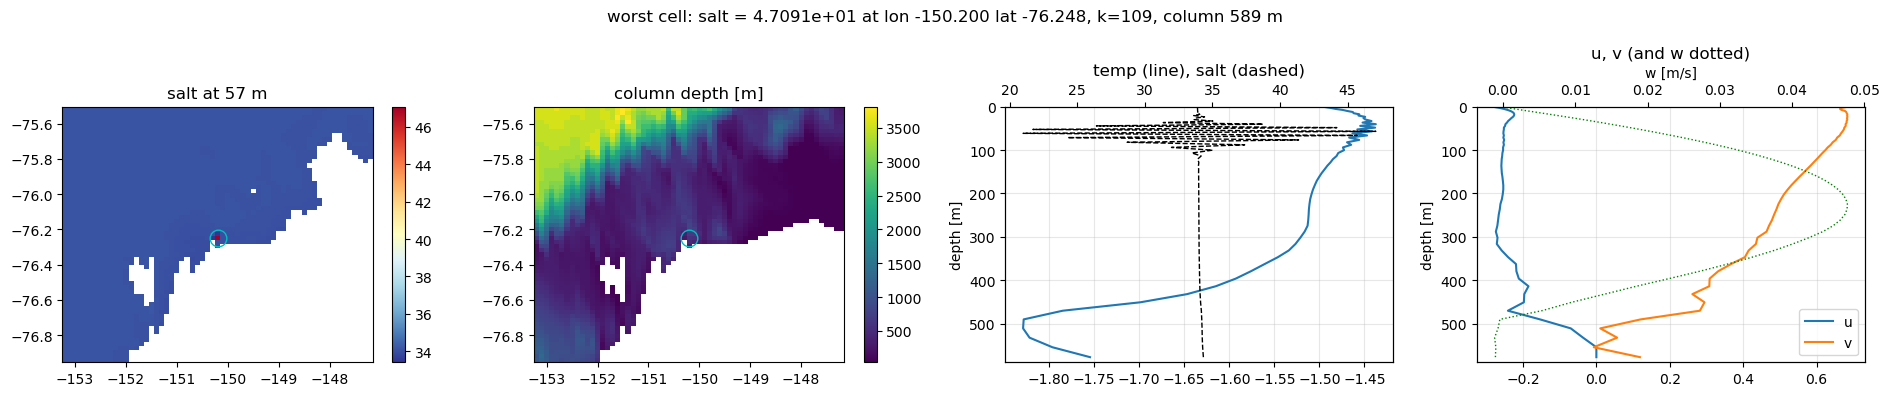

In [6]:
if worst:
    _, nm0, k0, j0g, i0g, val0 = worst[0]
    W = 30
    js, je = max(j0g-W, 0), min(j0g+W+1, ny)
    isl = np.arange(i0g-W, i0g+W+1) % nx
    xw = xt[isl].astype(float)
    xw = xw + 360.0*np.cumsum(np.concatenate([[0], np.diff(xw) < 0]))  # unwrap the seam

    pe, jb, ib = block_of(j0g, i0g)
    prof = {v: np.asarray(np.load(_npy(pe, v), mmap_mode='r'))[:, jb, ib]
            for v in ('temp', 'salt', 'u', 'v', 'w', 'kappaH_tke', 'tke')
            if os.path.exists(_npy(pe, v))}
    kw_ = nwet_col[j0g, i0g]
    d = depth_of[nz-kw_:]

    fld = mask(load(nm0, k0), k0)
    fig, ax = plt.subplots(1, 4, figsize=(19, 4))
    h = ax[0].pcolormesh(xw, yt[js:je], fld[js:je][:, isl], shading='auto')
    ax[0].plot(xw[W], yt[j0g], 'co', mfc='none', ms=12); plt.colorbar(h, ax=ax[0])
    ax[0].set_title('%s at %.0f m' % (nm0, depth_of[k0]))
    h = ax[1].pcolormesh(xw, yt[js:je], np.where(kbot > 0, col_depth, np.nan)[js:je][:, isl],
                         shading='auto', cmap='viridis')
    ax[1].plot(xw[W], yt[j0g], 'co', mfc='none', ms=12); plt.colorbar(h, ax=ax[1])
    ax[1].set_title('column depth [m]')
    ax[2].plot(prof['temp'][nz-kw_:], d, label='temp')
    a2 = ax[2].twiny(); a2.plot(prof['salt'][nz-kw_:], d, 'k--', lw=1, label='salt')
    ax[2].set_title('temp (line), salt (dashed)')
    ax[3].plot(prof['u'][nz-kw_:], d, label='u'); ax[3].plot(prof['v'][nz-kw_:], d, label='v')
    if 'w' in prof:
        a3 = ax[3].twiny(); a3.plot(prof['w'][nz-kw_:], d, 'g:', lw=1); a3.set_xlabel('w [m/s]')
    ax[3].legend(); ax[3].set_title('u, v (and w dotted)')
    for a in ax[2:]:
        a.set_ylim(col_depth[j0g, i0g], 0); a.set_ylabel('depth [m]'); a.grid(alpha=.3)
    fig.suptitle('worst cell: %s = %.4e at lon %.3f lat %.3f, k=%d, column %.0f m'
                 % (nm0, val0, xt[i0g], yt[j0g], k0, col_depth[j0g, i0g]))
    fig.tight_layout()

    print('profile of the column, surface first (depth, temp, salt, u, v, w):')
    for kk in range(nz-1, max(nz-kw_-1, nz-26), -1):
        print('  %7.1f m  %8.3f  %8.3f  %9.4f %9.4f %11.3e'
              % (depth_of[kk], prof['temp'][kk], prof['salt'][kk],
                 prof['u'][kk], prof['v'][kk], prof.get('w', np.zeros(nz))[kk]))

## 4. Is it the time step, or the forcing over the top cell?

Three numbers per cell, all evaluated from the dump itself:

    vertical CFL      |w| dt / dz            in every cell
    horizontal CFL    |u| dt / dx            with the true metric
    forcing over dz   |forc_T| dt / dz(top)  the temperature change the
                      surface flux alone makes in one step, in K

A vertical CFL above about 0.5 in the thin upper cells, or a surface
temperature change of order a kelvin per step, points at the time step. Both
well below, with the trouble in one geometrically enclosed cell, points at the
initial condition or the topography instead.

In [ ]:
R = 6370e3; d2m = R/180.0*np.pi
cost = np.cos(np.deg2rad(yt))
dxt = np.diff(np.concatenate([xt[:1] - (xt[1]-xt[0]), xt]))    # degrees
dyt = np.diff(np.concatenate([yt[:1] - (yt[1]-yt[0]), yt]))
dx = np.abs(dxt)[None, :]*cost[:, None]*d2m
dy = np.abs(dyt)[:, None]*d2m*np.ones_like(dx)
dz3 = dzt[:, None, None]

cflw = np.zeros((ny, nx)); cflh = np.zeros((ny, nx)); kw_max = np.zeros((ny, nx), int)
for pe, j0, j1, i0, i1 in BLOCKS:
    w = wet[:, j0:j1, i0:i1]
    W_ = np.where(w, np.abs(np.asarray(np.load(_npy(pe, 'w'), mmap_mode='r'))), 0.0)
    u = np.abs(np.asarray(np.load(_npy(pe, 'u'), mmap_mode='r')))
    v = np.abs(np.asarray(np.load(_npy(pe, 'v'), mmap_mode='r')))
    cw = W_*dt/dz3
    cflw[j0:j1, i0:i1] = cw.max(axis=0)
    kw_max[j0:j1, i0:i1] = cw.argmax(axis=0)
    cflh[j0:j1, i0:i1] = np.where(w, u*dt/dx[j0:j1, i0:i1] + v*dt/dy[j0:j1, i0:i1],
                                  0.0).max(axis=0)
fT = np.abs(mask(load('forc_temp_surface')))*dt/dzt[-1]
fS = np.abs(mask(load('forc_salt_surface')))*dt/dzt[-1]

for nm, a, thr in (('vertical CFL  |w| dt/dz', cflw, 0.5),
                   ('horizontal CFL |u| dt/dx', cflh, 0.5),
                   ('surface dT per step [K]', fT, 0.5),
                   ('surface dS per step', fS, 0.1)):
    a_ = np.where(kbot > 0, a, np.nan)
    n = int(np.nansum(a_ > thr))
    j, i = np.unravel_index(int(np.nanargmax(a_)), a_.shape)
    print('%-26s max %8.3f at lon %8.3f lat %8.3f | %d cells above %.2f'
          % (nm, np.nanmax(a_), xt[i], yt[j], n, thr))

fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
for a, fld, ttl, vmax in ((ax[0,0], np.where(kbot > 0, cflw, np.nan), 'vertical CFL', 1.0),
                          (ax[0,1], np.where(kbot > 0, cflh, np.nan), 'horizontal CFL', 1.0),
                          (ax[1,0], fT, 'surface dT per step [K]', 1.0),
                          (ax[1,1], fS, 'surface dS per step', 0.2)):
    h = a.pcolormesh(xt, yt, fld, shading='auto', vmin=0, vmax=vmax, cmap='magma_r')
    plt.colorbar(h, ax=a, extend='max'); a.set_title(ttl)
fig.tight_layout()

## 5. The history of that cell in the ordinary snapshots

The dump is one step. The snapshots before it say whether the cell was already
drifting, and how fast. If the column looks healthy in the last ordinary
snapshot and broken here, the event is faster than the snapshot interval and
the vertical CFL above is the number to trust.

In [ ]:
if worst:
    hist = []
    for d_ in segs:
        for p in sorted(glob.glob(os.path.join(d_, 'pe=0', 'n=*')),
                        key=lambda q: int(re.search(r'n=(\d+)$', q).group(1))):
            hist.append((d_, int(re.search(r'n=(\d+)$', p).group(1))))
    hist = [h for h in hist if h[1] <= step][-6:]
    pe, jb, ib = block_of(j0g, i0g)
    print('cell at lon %.3f lat %.3f, k=%d (%.1f m)' % (xt[i0g], yt[j0g], k0, depth_of[k0]))
    print('%12s %8s %10s %10s %10s %10s' % ('snapshot', 'step', 'temp', 'salt', 'u', 'w'))
    rows = []
    for d_, n_ in hist:
        try:
            g = lambda v: float(np.load(_npy(pe, v, d_, n_), mmap_mode='r')[k0, jb, ib])
            rows.append((n_, g('temp'), g('salt'), g('u'), g('w')))
            print('%12s %8d %10.4f %10.4f %10.4f %10.3e'
                  % (os.path.basename(d_)[-7:], n_, *rows[-1][1:]))
        except Exception as e:
            print('  step %d not readable (%r)' % (n_, e))
    g = lambda v: float(np.load(_npy(pe, v), mmap_mode='r')[k0, jb, ib])
    print('%12s %8d %10.4f %10.4f %10.4f %10.3e'
          % ('ALARM', step, g('temp'), g('salt'), g('u'), g('w')))
    if len(rows) > 1:
        r = np.array(rows)
        fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
        for a, c, ttl in ((ax[0], 1, 'temp'), (ax[1], 2, 'salt'), (ax[2], 3, 'u')):
            a.plot(r[:, 0], r[:, c], 'o-'); a.plot([step], [g(ttl)], 'r*', ms=14)
            a.set_xlabel('step'); a.set_title(ttl); a.grid(alpha=.3)
        fig.tight_layout()